# Train the GNNs

Trains one model family per compatible configuration and records every run for `BEG_05_Results`.
Four cells: discover, plan, review, execute.

> **The execute cell trains only when `CONFIRM_TRAINING = True` is set in the first cell.** Without
> it, the notebook plans and reviews but trains nothing.

**Runs are content-addressed.** `run_fingerprint` combines a fingerprint of the dataset with one of
the model and training code, the torch and CUDA build, and the hyperparameters, so a plan skips
finished work and results from different code revisions get different fingerprints. A run trained
under another torch/CUDA build counts as done when everything else matches, so runs copied from a
training machine are not trained again. The plan is reviewed before it runs.

**This notebook needs no database.** It reads only `outputs/pyg_datasets/`, so it can run on another
machine; see `docs/training-on-another-machine.md`. The full run is long enough to be worth moving to
a CUDA machine.

**What it produces**

```
outputs/GNNruns/<run>/run_meta.json          what was trained, and on what
outputs/GNNruns/<run>/history.csv            per-epoch train and validation loss
outputs/GNNruns/<run>/test_predictions.csv   per-model prediction and target
outputs/GNNruns/<run>/model_package.pt       the selected weights, with what rebuilds the model
outputs/GNNruns/<run>/model_state_dict.pt    the selected weights alone
outputs/GNNruns/<run>/last_checkpoint.pt     the state an interrupted run resumes from
outputs/GNNruns/<run>/_DONE.txt              written last, so a partial run is visible
outputs/GNNruns/run_index.csv                one row per run
```

**Before running**

- `BEG_03_Datasets` must have written all ten packages, or this notebook must have been given them.
- Check the device line in the first cell. The runner selects CUDA when it is available; the
  published experiment took 92 hours of training on an RTX 3060, and far longer on a CPU.

**Environment.** `pip install -e ".[notebooks,train]" matplotlib` installs what this notebook needs, and `pip install -e ".[all]"` what all five need. The first cell checks and prints the command for anything missing; `beg doctor` does the same for every notebook at once.

## Discover the packages, and say what this will train on

**Inputs**: `outputs/pyg_datasets/<config>/training_ready.{pt,meta.json}`.

**Steps**
1. Discover every training-ready package by directory, reading only the small metadata.
2. Report the device, the torch build and the implementation fingerprint.
3. Stop if the packages were built on different splits.
4. Report the torch/CUDA builds that trained the runs already on disk.

**Outputs**
- `CONFIRM_TRAINING`, `PACKAGES`, `RUNS_DIR`, `DEVICE`

**Used functions**
`beg.requirements.check_environment`, `load_training_ready_packages`, `implementation_fingerprint`, `dataset_fingerprint`,
`runs_from_other_builds`

In [1]:
from beg.requirements import check_environment

check_environment("BEG_04_Train")  # names anything missing, and the pip command that adds it

# False stops the execute cell before it trains anything. Set True only to train on this machine.
CONFIRM_TRAINING = False

import warnings

import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
# The C5 and C10 weather node only sends messages; PyG warns that it is never updated
warnings.filterwarnings("ignore", message=".*There exist node types.*")

import torch

from beg.settings import display_path, output_dir
from beg.train.guard import runs_from_other_builds
from beg.train.runner import (
    dataset_fingerprint,
    implementation_fingerprint,
    load_training_ready_packages,
)

DATASETS_DIR = output_dir() / "pyg_datasets"
RUNS_DIR = output_dir() / "GNNruns"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

PACKAGES = load_training_ready_packages(DATASETS_DIR)

# CUDA if available, otherwise CPU. MPS is not used: PyG's scatter operations lack MPS kernels.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# All packages must share one split
split_hashes = {cfg: p["metadata"]["split"]["train_ids_sha"] for cfg, p in PACKAGES.items()}
if len(set(split_hashes.values())) != 1:
    raise RuntimeError(
        "The packages were not built on one split, so their results would not be "
        f"comparable. Distinct train-id hashes: {sorted(set(split_hashes.values()))}"
    )

inventory = pd.DataFrame(
    [
        {
            "config": cfg,
            "graph_kind": p["metadata"]["graph_kind"],
            "n_graphs": p["metadata"]["n_graphs"],
            "train/val/test": "/".join(str(v) for v in p["metadata"]["split_sizes"].values()),
            "dataset_fingerprint": dataset_fingerprint(p["metadata"])[:12],
        }
        for cfg, p in sorted(PACKAGES.items())
    ]
)

print(f"device       : {DEVICE.upper()}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"torch        : {torch.__version__}, cuda build {torch.version.cuda}")
print(f"code         : implementation fingerprint {implementation_fingerprint()[:12]}")
print(f"packages     : {len(PACKAGES)} from {display_path(DATASETS_DIR)}")
print(f"runs         : {display_path(RUNS_DIR)}")
for build, n in runs_from_other_builds(RUNS_DIR, (torch.__version__, torch.version.cuda)).most_common():
    print(f"               {n} trained with {build}")
print(f"training     : {'confirmed' if CONFIRM_TRAINING else 'not confirmed - the execute cell trains nothing'}")

inventory

environment ok for BEG_04_Train
device       : CPU
torch        : 2.14.0, cuda build None
code         : implementation fingerprint 452eca681964
packages     : 10 from outputs/pyg_datasets
runs         : outputs/GNNruns
               816 trained with torch 2.6.0+cu124, CUDA 12.4
training     : not confirmed - the execute cell trains nothing


,config,graph_kind,n_graphs,train/val/test,dataset_fingerprint
0,C10_component_hetero_external_weather,hetero,13260,9282/1326/2652,61ec1b8ca75a
1,C1_zone_homo_no_weather,homo,13260,9282/1326/2652,4c1f0a15d74e
2,C2_zone_homo_graph_weather,homo,13260,9282/1326/2652,9cb6eb673186
3,C3_zone_hetero_no_weather,hetero,13260,9282/1326/2652,175e3fe117e5
4,C4_zone_hetero_building_weather,hetero,13260,9282/1326/2652,364053b0ef44
5,C5_zone_hetero_external_weather,hetero,13260,9282/1326/2652,d1ef60fc5552
6,C6_component_homo_no_weather,homo,13260,9282/1326/2652,63138db7dd5f
7,C7_component_homo_graph_weather,homo,13260,9282/1326/2652,95eb46528c20
8,C8_component_hetero_no_weather,hetero,13260,9282/1326/2652,9ee943b484ea
9,C9_component_hetero_building_weather,hetero,13260,9282/1326/2652,d55324af85c9


## Choose a bounded plan

The plan: which model families, how many variants of each, and against which configurations.

`VARIANT_BUDGETS` caps the search per family. The published experiment used **24 variants per model
per configuration** — 816 runs — sampled deterministically from a much larger space (144 to 576
variants per family, see the table in the next cell). The paper reports the best variant found for
each pair, so a smaller budget changes the results.

On the 200-model subset with `SMOKE_TEST`, `heterogin` variant 1 reaches no finite validation loss
on C8, C9 and C10, so at a budget of 1 those pairs have no result. On the full set all 816 runs
complete.

Model families are matched to the configurations they can read: the four homogeneous families take
C1, C2, C6 and C7; the three heterogeneous ones take C3, C4, C5, C8, C9 and C10: 34 pairs, crossed
by `build_training_plan`. `match_runs_from_other_builds` then marks as done the planned runs that
another torch/CUDA build already trained with the same data, code and hyperparameters.

**`SMOKE_TEST` first, on a machine you have not trained on before.** It caps epochs so the whole
path — load, train, evaluate, write — runs in minutes. Smoke-test runs get their own fingerprints,
so the full runs remain queued.

**Outputs**
- `TRAINING_PLAN` and `PLAN_DF`, reviewed in the next cell before anything runs

**Used functions**
`expand_model_jobs`, `build_training_plan`, `match_runs_from_other_builds`, `training_plan_dataframe`

In [2]:
from beg.train.dashboard import training_plan_dataframe
from beg.train.guard import match_runs_from_other_builds
from beg.train.runner import build_training_plan
from beg.train.search import BASE_TRAINING_CONFIG, expand_model_jobs

MODEL_KEYS = ["gcn", "sage_attn", "gin_mean", "gin_set2set", "rgcn", "heterosage", "heterogin"]
# Published: 24 variants per model per configuration, 816 runs, 92 h of training on an RTX 3060.
# The paper reports the best variant per pair, so fewer variants change the results.
VARIANT_BUDGETS = dict.fromkeys(MODEL_KEYS, 24)
TARGET_CONFIGS = None                            # None for all ten; or e.g. ["C1_zone_homo_no_weather"]

TRAIN_SEED = int(BASE_TRAINING_CONFIG["train_seed"])

# Off for the published runs: results are reproducible in data, split, code and
# hyperparameters, not bit-for-bit in the weights. True forces slower kernels.
DETERMINISTIC = False

RETRY_INTERRUPTED = False   # True to re-attempt runs left incomplete by a crash

SMOKE_TEST = False          # True: cap epochs to prove the environment works
SMOKE_EPOCHS = 2

train_overrides = {"max_epochs": SMOKE_EPOCHS, "patience": SMOKE_EPOCHS} if SMOKE_TEST else None

SEARCH_JOBS = expand_model_jobs(
    model_keys=MODEL_KEYS,
    max_variants_per_model=VARIANT_BUDGETS,
    seed=TRAIN_SEED,
    train_overrides=train_overrides,
)
ACTIVE_CONFIGS = sorted(PACKAGES) if TARGET_CONFIGS is None else [
    name for name in TARGET_CONFIGS if name in PACKAGES
]

TRAINING_PLAN = build_training_plan(
    payloads=PACKAGES,
    jobs=SEARCH_JOBS,
    runs_dir=RUNS_DIR,
    target_configs=ACTIVE_CONFIGS,
    deterministic=DETERMINISTIC,
    retry_incomplete=RETRY_INTERRUPTED,
)
TRAINING_PLAN = match_runs_from_other_builds(TRAINING_PLAN, runs_dir=RUNS_DIR, deterministic=DETERMINISTIC)
PLAN_DF = training_plan_dataframe(TRAINING_PLAN)

actions = PLAN_DF["action"].value_counts().to_dict()
print(f"{'SMOKE TEST - ' if SMOKE_TEST else ''}{len(ACTIVE_CONFIGS)} configurations x "
      f"{len(SEARCH_JOBS)} model variants -> {len(PLAN_DF)} compatible runs")
batch_sizes = sorted({job['train_hparams']['batch_size'] for job in SEARCH_JOBS})
print(f"max epochs   : {SEARCH_JOBS[0]['train_hparams']['max_epochs']}, "
      f"patience {SEARCH_JOBS[0]['train_hparams']['patience']}, "
      f"batch {' or '.join(map(str, batch_sizes))}")
print(f"actions      : {actions}")

PLAN_DF.groupby(["action", "model_key"]).size().unstack(fill_value=0)

10 configurations x 168 model variants -> 816 compatible runs
max epochs   : 100, patience 10, batch 16 or 32
actions      : {'skip_done_other_build': 816}


model_key,gcn,gin_mean,gin_set2set,heterogin,heterosage,rgcn,sage_attn
action,,,,,,,
skip_done_other_build,96,96,96,144,144,144,96


## Review the coverage before committing to it

What exists already, what the plan adds, and where the gaps are — read *before* a run that may take
hours. The matrix is configuration against model family; each cell counts the planned runs that are
complete, including those another torch/CUDA build trained.

Nothing here trains anything.

**Outputs**
- `COVERAGE_MATRIX`, `COVERAGE_BY_CONFIG`, and the coverage figure

**Used functions**
`discover_run_inventory`, `build_coverage_tables`, `plot_coverage_matrix`,
`proposed_search_space_df`

planned runs already complete: 816 of 816
this plan would train: 0


,model_key,graph_kind,description
0,gcn,homo,Homogeneous GCN baseline with mean pooling.
1,gin_mean,homo,Homogeneous GIN with mean pooling.
2,gin_set2set,homo,Homogeneous GIN with Set2Set readout.
3,heterogin,hetero,Heterogeneous GIN using edge attributes throug...
4,heterosage,hetero,Heterogeneous GraphSAGE with per-type pooling.
5,rgcn,hetero,Relation-specific linear message passing with ...
6,sage_attn,homo,Homogeneous GraphSAGE with attentional readout.


,config,selected_variants,completed_variants,failed_variants,interrupted_variants
0,C1_zone_homo_no_weather,96,96,0,0
1,C2_zone_homo_graph_weather,96,96,0,0
2,C3_zone_hetero_no_weather,72,72,0,0
3,C4_zone_hetero_building_weather,72,72,0,0
4,C5_zone_hetero_external_weather,72,72,0,0
5,C6_component_homo_no_weather,96,96,0,0
6,C7_component_homo_graph_weather,96,96,0,0
7,C8_component_hetero_no_weather,72,72,0,0
8,C9_component_hetero_building_weather,72,72,0,0
9,C10_component_hetero_external_weather,72,72,0,0


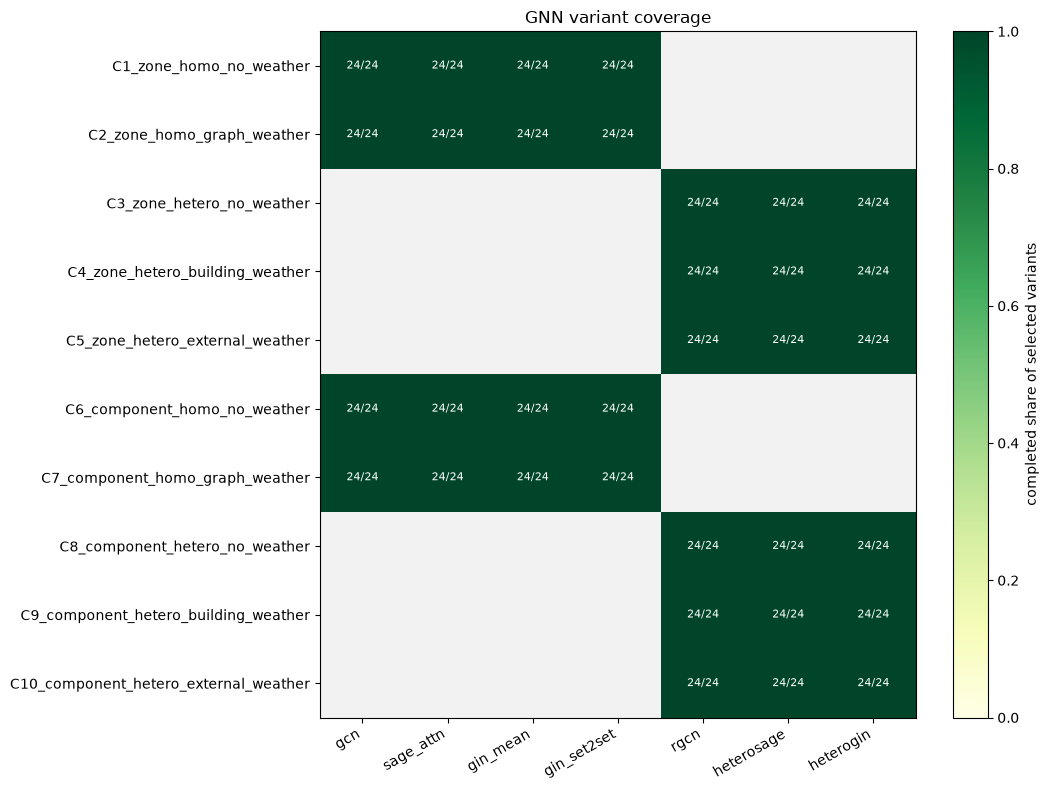

model_key,gcn,sage_attn,gin_mean,gin_set2set,rgcn,heterosage,heterogin
config,,,,,,,
C1_zone_homo_no_weather,24/24,24/24,24/24,24/24,0/0,0/0,0/0
C2_zone_homo_graph_weather,24/24,24/24,24/24,24/24,0/0,0/0,0/0
C3_zone_hetero_no_weather,0/0,0/0,0/0,0/0,24/24,24/24,24/24
C4_zone_hetero_building_weather,0/0,0/0,0/0,0/0,24/24,24/24,24/24
C5_zone_hetero_external_weather,0/0,0/0,0/0,0/0,24/24,24/24,24/24
C6_component_homo_no_weather,24/24,24/24,24/24,24/24,0/0,0/0,0/0
C7_component_homo_graph_weather,24/24,24/24,24/24,24/24,0/0,0/0,0/0
C8_component_hetero_no_weather,0/0,0/0,0/0,0/0,24/24,24/24,24/24
C9_component_hetero_building_weather,0/0,0/0,0/0,0/0,24/24,24/24,24/24


In [3]:
from beg.report.style import show
from beg.train.dashboard import (
    build_coverage_tables,
    discover_run_inventory,
    plot_coverage_matrix,
)
from beg.train.guard import DONE_ACTIONS, TRAINING_ACTIONS
from beg.train.search import proposed_search_space_df

RUN_INVENTORY = discover_run_inventory(RUNS_DIR)
COVERAGE_DETAIL, COVERAGE_MATRIX, COVERAGE_BY_CONFIG = build_coverage_tables(
    inventory=RUN_INVENTORY,
    plan=TRAINING_PLAN,
    configs=ACTIVE_CONFIGS,
    model_keys=MODEL_KEYS,
)

complete = int(PLAN_DF["action"].isin(DONE_ACTIONS).sum())
runnable = int(PLAN_DF["action"].isin(TRAINING_ACTIONS).sum())
print(f"planned runs already complete: {complete} of {len(PLAN_DF)}")
print(f"this plan would train: {runnable}")

display(proposed_search_space_df()[["model_key", "graph_kind", "description"]])
display(COVERAGE_BY_CONFIG)

coverage_figure, _ = plot_coverage_matrix(COVERAGE_DETAIL)
show(coverage_figure)

COVERAGE_MATRIX

## Execute the reviewed plan

Runs what the cell above showed. If the plan trains anything, the cell first requires
`CONFIRM_TRAINING = True`, and otherwise stops and says how many runs it would train. Each run writes
its metadata first and `_DONE.txt` last, so an interrupted run is marked incomplete; with
`RETRY_INTERRUPTED = True`, the next plan resumes it from its last checkpoint.

`continue_on_error=True`: a failing run is recorded and the plan continues. Failures appear in
`RUN_RESULTS` with their message, and the coverage matrix keeps the gap visible.

**Outputs**
- One directory per run under `outputs/GNNruns/`, and `run_index.csv`
- `RUN_RESULTS`, and the coverage after the run when it trained anything

**Used functions**
`require_training_confirmed`, `run_training_plan`, `write_run_index`

In [4]:
import time

from beg.train.dashboard import write_run_index
from beg.train.guard import require_training_confirmed
from beg.train.runner import run_training_plan

require_training_confirmed(
    TRAINING_PLAN,
    confirmed=CONFIRM_TRAINING,
    build=(torch.__version__, torch.version.cuda),
    device=DEVICE,
)

t0 = time.perf_counter()
RUN_RESULTS = run_training_plan(
    TRAINING_PLAN,
    runs_dir=RUNS_DIR,
    deterministic=DETERMINISTIC,
    continue_on_error=True,
)
elapsed = time.perf_counter() - t0

# Rewrites run_index.csv and returns the inventory it wrote
RUN_INVENTORY = write_run_index(RUNS_DIR)
index_path = RUNS_DIR / "run_index.csv"
COVERAGE_DETAIL, COVERAGE_MATRIX, COVERAGE_BY_CONFIG = build_coverage_tables(
    inventory=RUN_INVENTORY,
    plan=TRAINING_PLAN,
    configs=ACTIVE_CONFIGS,
    model_keys=MODEL_KEYS,
)

status_counts = RUN_RESULTS["status"].value_counts().to_dict() if not RUN_RESULTS.empty else {}
print(f"finished in {elapsed / 60:.1f} min on {DEVICE.upper()}: {status_counts}")
print(f"run index -> {display_path(index_path)}")

failed = RUN_RESULTS.loc[RUN_RESULTS["status"] == "failed"] if not RUN_RESULTS.empty else RUN_RESULTS
if len(failed):
    print(f"\n{len(failed)} run(s) failed - the rest are unaffected:")
    display(failed[["config", "model_key", "error"]])

trained = int(RUN_RESULTS["status"].isin(["done", "failed"]).sum()) if not RUN_RESULTS.empty else 0
if trained:
    display(COVERAGE_BY_CONFIG)
    coverage_figure, _ = plot_coverage_matrix(COVERAGE_DETAIL, title="Coverage after this run")
    show(coverage_figure)
    display(COVERAGE_MATRIX)
else:
    print("nothing trained: the coverage above is unchanged")

Selected GNN runs: 0run [00:00, ?run/s]
finished in 0.0 min on CPU: {'skip_done_other_build': 816}
run index -> outputs/GNNruns/run_index.csv
nothing trained: the coverage above is unchanged


---

**Next:** `BEG_05_Results` reads the run directories under `outputs/GNNruns/` and turns them into
the paper's tables and figures.

If this ran on another machine, that is the directory to bring back: about 13 GB for the full
experiment, mostly model checkpoints, and the only thing the results depend on.